In [78]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt  # for making figures
%matplotlib inline

In [79]:
# Read in all the words
words = open('../names.txt', 'r').read().splitlines()

In [80]:
# Build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s: i + 1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i: s for s, i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [81]:
# build the dataset

block_size = 3  # context length: how many characters do we take to predict the next one?
X, Y = [], []
for w in words[:5]:
    context = [0] * block_size
    for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        context = context[1:] + [ix]  # crop and append

X = torch.tensor(X)
Y = torch.tensor(Y)


In [82]:
# Initialize the model parameters.
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)

parameters = [C, W1, b1, W2, b2]
sum(p.numel() for p in parameters)

3481

In [83]:
for p in parameters:
    p.requires_grad = True

In [84]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10 ** lre

In [85]:
lri = []
lossi = []

for i in range(1000):

    # minibatch construct
    ix = torch.randint(0, X.shape[0], (32,))

    # forward pass
    emb = C[X[ix]]  # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)  # (32, 100)
    logits = h @ W2 + b2  # (32, 27)
    loss = F.cross_entropy(logits, Y[ix])
    print(loss.item())

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = lrs[i]
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    lri.append(lr)
    lossi.append(loss.item())




20.82396697998047
15.384184837341309
14.339093208312988
17.405710220336914
14.852673530578613
17.118635177612305
18.91860008239746
16.126678466796875
18.224071502685547
16.75435447692871
16.606956481933594
17.48964500427246
16.206090927124023
17.737140655517578
14.86739730834961
15.904426574707031
15.508541107177734
18.44913673400879
14.310996055603027
16.809980392456055
15.401432037353516
16.781946182250977
14.790155410766602
14.98337173461914
17.49464988708496
17.992900848388672
19.583810806274414
14.306402206420898
18.318185806274414
17.191099166870117
16.73890495300293
14.41297721862793
16.89876365661621
15.960564613342285
15.20383071899414
14.147407531738281
15.465241432189941
14.896201133728027
14.287691116333008
12.939523696899414
20.303348541259766
16.75192642211914
14.518211364746094
15.513570785522461
15.359378814697266
16.273221969604492
14.68048095703125
14.775233268737793
12.54570198059082
15.61726188659668
12.613157272338867
15.7147216796875
15.978160858154297
14.70169734

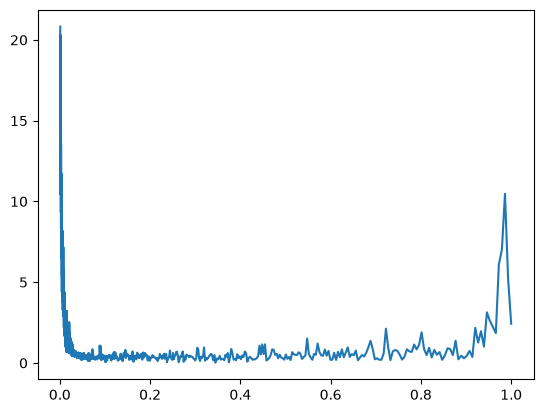

In [86]:
plt.plot(lri, lossi)